# Sesión 5/6 · Árboles de decisión, Random Forest y boosting
**IA aplicada a la ciberseguridad · Máster en Ciberseguridad**  
**Versión didáctica para principiantes · Incluye todos los retos originales resueltos.**

En un sistema de detección de intrusiones (IDS) no basta con obtener una cifra de precisión: necesitamos saber **qué señales utiliza un detector, qué errores comete y si seguirá funcionando cuando cambie el tráfico**. Esta sesión parte de un árbol que toma una decisión mediante preguntas sencillas y termina comprobando cómo un resultado aparentemente excelente puede esconder un atajo.

| Parte | Problema que resolveremos | Aprendizaje clave |
|:--|:--|:--|
| **A** | ¿Cómo decide un árbol dónde partir los datos? | Impureza de Gini, cortes y ganancia. |
| **B** | ¿Cómo elegir y explicar un árbol? | Validación cruzada, ajuste, reglas y generalización. |
| **C** | ¿Por qué combinar árboles? | Random Forest, OOB, importancia y correlación. |
| **D** | ¿Qué hace el boosting y cuándo se detiene? | Errores secuenciales, *log-loss*, parada temprana. |
| **E** | ¿Puede engañarnos una exactitud del 99,9 %? | Atajos, huellas de herramientas y evaluación temporal. |
| **F** | ¿Es robusto el modelo frente a cambios sencillos? | Prueba de evasión **ilustrativa**, límites y defensas. |

**Datos:** las partes A–D y F usan **NSL-KDD** (conexiones de red etiquetadas como normales o ataques); la parte E usa **flujos sintéticos** generados por el curso. Son **dos experimentos diferentes**, con distribuciones y columnas distintas: sus métricas no son directamente comparables.

## Antes de empezar · Qué significa entrenar, validar y probar

Imagina que cada conexión es una **fila de una tabla**. Las **características** (*features*, también llamadas variables de entrada) son las columnas que describen la conexión: duración, bytes enviados, número de conexiones relacionadas, etc. La **etiqueta** es la respuesta que queremos predecir: `0 = normal`, `1 = ataque`.

- **Entrenar:** mostrar al algoritmo ejemplos con sus etiquetas para que aprenda reglas. En `fit(X, y)`, `X` contiene las características e `y` las etiquetas.
- **Predecir:** aplicar las reglas aprendidas a filas nuevas mediante `predict(X_nuevo)`. `predict_proba` devuelve puntuaciones entre 0 y 1 interpretadas como probabilidades estimadas por el modelo (no necesariamente bien calibradas).
- **Validar:** comparar distintas decisiones de diseño usando datos que no se utilizaron para entrenar ese modelo concreto. Se pueden usar particiones del conjunto de entrenamiento.
- **Probar (test):** medir el rendimiento final sobre datos apartados. **No** debemos elegir hiperparámetros mirando los resultados del test.

Un **hiperparámetro** es una decisión que fijamos *antes* de ajustar un modelo (por ejemplo, la profundidad máxima de un árbol). Un **parámetro aprendido** es algo que el modelo descubre durante el entrenamiento (por ejemplo, «`count > 23.5`»).

**Métricas que aparecerán:**

| Métrica | Qué mide | Ejemplo con 100 conexiones |
|:--|:--|:--|
| **Accuracy / exactitud** | Predicciones acertadas ÷ todas las conexiones. | 95 aciertos → 95 %. |
| **Recall de ataque / sensibilidad** | Ataques detectados ÷ ataques reales: `TP/(TP+FN)`. | 8 ataques detectados de 10 → 80 %. |
| **Precisión (*precision*)** | Alertas de ataque correctas ÷ todas las alertas: `TP/(TP+FP)`. | 8 alertas válidas de 16 → 50 %. |
| **AP / Average Precision** | Resumen de la curva precisión–recall al variar el umbral; valores mayores suelen indicar mejor ordenación de ataques. | No es lo mismo que accuracy ni que la precisión de un solo umbral. |

`TP` = ataque detectado; `FN` = ataque no detectado; `FP` = normal marcado como ataque. Ejemplo del peligro de accuracy: con **990 normales y 10 ataques**, predecir «normal» siempre consigue **99 % de accuracy y 0 % de recall**.

**Ejecución:** usa `Mayús + Intro` o «Ejecutar todas» desde un kernel reiniciado. El *kernel* es la memoria temporal de Python: si reinicias, se pierden las variables pero no los archivos guardados. El cuaderno es independiente de los anteriores; genera su propio `ia_utils.py` y descarga NSL-KDD si no está en `data/` (necesita Internet la primera vez). Las celdas de los retos ya contienen soluciones ejecutables y **no sobrescriben** los modelos principales.

## Preparación · Dependencias y funciones del curso

**Objetivo:** construir un punto de partida reproducible. `NumPy` realiza cálculos numéricos; `pandas` trata tablas; `Matplotlib` dibuja; `scikit-learn` implementa y evalúa árboles y bosques; `XGBoost` es otra biblioteca de *boosting*.

Si falta una biblioteca, el cuaderno intenta instalarla con `pip` en el entorno Python activo. Una instalación puede exigir reiniciar el kernel en algunos entornos. **La carpeta `data/` conserva los archivos NSL-KDD entre ejecuciones.**

In [2]:
# 1) Comprobar que las bibliotecas del cuaderno estén disponibles.
# importlib.util.find_spec permite comprobar si un módulo existe SIN importarlo todavía.
import importlib.util
import subprocess
import sys

bibliotecas_requeridas = {
    'numpy': 'numpy',
    'pandas': 'pandas',
    'matplotlib': 'matplotlib',
    'sklearn': 'scikit-learn',
    'seaborn': 'seaborn',
    'joblib': 'joblib',
    'xgboost': 'xgboost',
    'lightgbm': 'lightgbm',
}
paquetes_ausentes = [
    paquete_pip
    for nombre_modulo, paquete_pip in bibliotecas_requeridas.items()
    if importlib.util.find_spec(nombre_modulo) is None
]
print('=== COMPROBACIÓN DEL ENTORNO ===')
print(f'Python: {sys.version.split()[0]}')
print(f'Entorno: {"Google Colab" if "google.colab" in sys.modules else "Jupyter / VS Code / Codespaces"}')
if paquetes_ausentes:
    print('Se instalarán estas dependencias:', ', '.join(paquetes_ausentes))
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *paquetes_ausentes])
else:
    print('Dependencias: todas las bibliotecas del cuaderno están disponibles.')

=== COMPROBACIÓN DEL ENTORNO ===
Python: 3.12.3
Entorno: Jupyter / VS Code / Codespaces
Dependencias: todas las bibliotecas del cuaderno están disponibles.


### Las funciones auxiliares del curso

La siguiente celda crea `ia_utils.py`, un **módulo** (archivo Python importable) que contiene las funciones originales del curso. Entre ellas: `load_nsl_kdd` (carga los archivos reales y añade `is_attack`), `add_category` (agrupa tipos de ataque) y `generar_flujos` (crea los flujos artificiales de la parte E). **Su implementación original se conserva sin cambios**: no es el contenido que estamos aprendiendo en esta sesión, por eso la celda puede aparecer plegada.

`write_text` **sustituye** el contenido de `ia_utils.py`: ejecutar la celda dos veces no añade ni duplica funciones. `importlib.reload` vuelve a cargar el módulo incluso si ya estaba en memoria.

In [3]:
# 2) Guardar exactamente las utilidades entregadas por el curso en un módulo importable.
# La cadena IA_UTILS es código fuente; no son datos de NSL-KDD.
from pathlib import Path
import importlib

IA_UTILS = r'''"""Funciones del curso IA aplicada a la ciberseguridad (sesiones 3 a 6)."""
import os, re, urllib.request
import numpy as np
import pandas as pd

NSL_URL = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/"
NSL_COLS = ["duration","protocol_type","service","flag","src_bytes","dst_bytes","land",
  "wrong_fragment","urgent","hot","num_failed_logins","logged_in","num_compromised",
  "root_shell","su_attempted","num_root","num_file_creations","num_shells",
  "num_access_files","num_outbound_cmds","is_host_login","is_guest_login","count",
  "srv_count","serror_rate","srv_serror_rate","rerror_rate","srv_rerror_rate",
  "same_srv_rate","diff_srv_rate","srv_diff_host_rate","dst_host_count",
  "dst_host_srv_count","dst_host_same_srv_rate","dst_host_diff_srv_rate",
  "dst_host_same_src_port_rate","dst_host_srv_diff_host_rate","dst_host_serror_rate",
  "dst_host_srv_serror_rate","dst_host_rerror_rate","dst_host_srv_rerror_rate",
  "label","difficulty"]


def load_nsl_kdd(split="train", base="data"):
    """Carga NSL-KDD y añade la columna is_attack. Descarga los ficheros si faltan."""
    name = "KDDTrain+.txt" if split == "train" else "KDDTest+.txt"
    path = os.path.join(base, name)
    if not os.path.exists(path):
        os.makedirs(base, exist_ok=True)
        urllib.request.urlretrieve(NSL_URL + name.replace("+", "%2B"), path)
    df = pd.read_csv(path, header=None, names=NSL_COLS)
    df["is_attack"] = (df["label"] != "normal").astype(int)
    return df


ATTACK_MAP = {"normal": "normal",
  **{a: "dos" for a in ["back", "land", "neptune", "pod", "smurf", "teardrop",
                        "apache2", "udpstorm", "processtable", "mailbomb"]},
  **{a: "probe" for a in ["satan", "ipsweep", "nmap", "portsweep", "mscan", "saint"]},
  **{a: "r2l" for a in ["guess_passwd", "ftp_write", "imap", "phf", "multihop",
                        "warezmaster", "warezclient", "spy", "xlock", "xsnoop",
                        "snmpguess", "snmpgetattack", "httptunnel", "sendmail",
                        "named", "worm"]},
  **{a: "u2r" for a in ["buffer_overflow", "loadmodule", "rootkit", "perl",
                        "sqlattack", "xterm", "ps"]}}


def add_category(df):
    """Añade la columna category: normal, dos, probe, r2l o u2r."""
    df["category"] = df["label"].map(ATTACK_MAP)
    return df


def generar_flujos(n=60_000, frac_ataque=0.25, seed=0, cambio_herramienta=False):
    """Flujos de red sintéticos con columnas al estilo CICIDS2017, incluidos sus defectos
    (espacios en los nombres, infinitos, nulos y duplicados). Etiquetas BENIGN / DDoS.
    Con cambio_herramienta=True el ataque llega en dos episodios con herramientas distintas."""
    rng = np.random.default_rng(seed)
    nb, na = int(n * (1 - frac_ataque)), int(n * frac_ataque)
    t0 = pd.Timestamp("2017-07-07 09:00:00")
    # --- tráfico benigno
    port_b = rng.choice([443, 80, 53, 22, 8080, 3389, 0], nb, p=[.40, .20, .20, .05, .05, .02, .08])
    port_b = np.where(port_b == 0, rng.integers(1024, 65535, nb), port_b)
    dur_b = np.where(rng.random(nb) < 0.02, 0, rng.lognormal(11, 2, nb)).astype(int)
    fwd_b = rng.poisson(8, nb) + 1
    bwd_b = rng.poisson(7, nb)
    fwl_b = np.where(rng.random(nb) < 0.15, rng.uniform(0, 10, nb), rng.normal(400, 250, nb)).clip(0)
    bwl_b = rng.normal(700, 400, nb).clip(0)
    syn_b = (rng.random(nb) < 0.3).astype(int)
    win_b = rng.choice([29200, 65535, 8192, 14600, 64240, -1], nb, p=[.25, .25, .15, .1, .15, .1])
    ts_b = rng.uniform(0, 8 * 3600, nb)
    # --- ataque
    if cambio_herramienta:
        epi = rng.random(na) < 0.5
        ts_a = np.where(epi, rng.uniform(1 * 3600, 2 * 3600, na), rng.uniform(5 * 3600, 6 * 3600, na))
        port_a = np.where(epi, 80, rng.choice([8080, 443], na))
        win_a = np.where(epi, 8192, rng.choice([29200, 65535, 64240], na))
        fwl_a = np.where(epi, rng.normal(8, 6, na), rng.normal(60, 40, na)).clip(0)
    else:
        ts_a = rng.uniform(6.9 * 3600, 7.3 * 3600, na)
        port_a = np.where(rng.random(na) < 0.9, 80, 443)
        win_a = np.where(rng.random(na) < 0.95, 8192, 29200)
        fwl_a = rng.normal(8, 6, na).clip(0)
    dur_a = rng.lognormal(13, 1.5, na).astype(int)
    fwd_a = rng.poisson(4, na) + 1
    bwd_a = rng.poisson(3, na)
    bwl_a = rng.normal(1500, 600, na).clip(0)
    syn_a = (rng.random(na) < 0.6).astype(int)

    def bloque(port, dur, fwd, bwd, fwl, bwl, syn, win, ts, label):
        tot_f, tot_b = fwd * fwl, bwd * bwl
        seg = np.maximum(dur, 0) / 1e6
        with np.errstate(divide="ignore", invalid="ignore"):
            fbs = (tot_f + tot_b) / seg
            fps = (fwd + bwd) / seg
            iat = np.where(fwd + bwd > 1, dur / np.maximum(fwd + bwd - 1, 1), np.nan)
        return pd.DataFrame({
            " Destination Port": port, " Flow Duration": dur, " Total Fwd Packets": fwd,
            " Total Backward Packets": bwd, "Total Length of Fwd Packets": tot_f.round(1),
            " Total Length of Bwd Packets": tot_b.round(1), " Fwd Packet Length Mean": fwl.round(2),
            " Bwd Packet Length Mean": bwl.round(2), "Flow Bytes/s": fbs, " Flow Packets/s": fps,
            " Flow IAT Mean": iat, " SYN Flag Count": syn, " ACK Flag Count": (rng.random(len(port)) < 0.85).astype(int),
            "Init_Win_bytes_forward": win, " Avg Fwd Segment Size": fwl.round(2),
            " Timestamp": t0 + pd.to_timedelta(ts, unit="s"), " Label": label})

    df = pd.concat([bloque(port_b, dur_b, fwd_b, bwd_b, fwl_b, bwl_b, syn_b, win_b, ts_b, "BENIGN"),
                    bloque(port_a, dur_a, fwd_a, bwd_a, fwl_a, bwl_a, syn_a, win_a, ts_a, "DDoS")], ignore_index=True)
    df.loc[rng.random(len(df)) < 0.001, "Flow Bytes/s"] = np.nan
    df = pd.concat([df, df.sample(frac=0.01, random_state=seed)], ignore_index=True)
    return df.sort_values(" Timestamp").reset_index(drop=True)


def generar_authlog(ruta="auth.log", n_atacantes=12, seed=42):
    """auth.log sintético de la sesión 2: 40 IP legítimas y n_atacantes IP de fuerza bruta (203.0.113.0/24)."""
    import datetime as dt
    rng = np.random.default_rng(seed); start = dt.datetime(2026, 10, 1)
    users = ["root", "admin", "carlos", "ana", "luis", "deploy", "test", "oracle", "ubuntu", "postgres"]
    rows = []
    for i in range(40):
        ip = f"10.10.10.{10 + i}"
        for t in rng.uniform(0, 7 * 24 * 3600, rng.integers(5, 40)):
            rows.append((start + dt.timedelta(seconds=float(t)), bool(rng.random() > 0.08), str(rng.choice(users[2:6])), ip))
    for i in range(n_atacantes):
        ip = f"203.0.113.{20 + i}"; t0 = rng.uniform(0, 7 * 24 * 3600 - 3600)
        for t in t0 + np.sort(rng.uniform(0, 1800, rng.integers(60, 400))):
            rows.append((start + dt.timedelta(seconds=float(t)), False, str(rng.choice(users)), ip))
    rows.sort(key=lambda r: r[0])
    with open(ruta, "w") as f:
        for ts, ok, user, ip in rows:
            v = "Accepted" if ok else "Failed"
            f.write(f"{ts:%b %d %H:%M:%S} srv sshd[{rng.integers(1000, 9999)}]: {v} password "
                    f"for {user} from {ip} port {rng.integers(1024, 65000)} ssh2\n")
    return ruta


def auth_features(ruta="auth.log"):
    """Características por IP y ventana de 10 minutos. La columna verdad solo sirve para evaluar."""
    pat = re.compile(r"^(\w{3}\s+\d+ \d\d:\d\d:\d\d) \S+ sshd\[\d+\]: (Failed|Accepted) password for (\S+) from (\S+) port")
    reg = []
    for linea in open(ruta):
        m = pat.match(linea)
        if m:
            reg.append((pd.to_datetime("2026 " + m.group(1), format="%Y %b %d %H:%M:%S"),
                        m.group(2) == "Accepted", m.group(3), m.group(4)))
    log = pd.DataFrame(reg, columns=["ts", "ok", "user", "ip"])
    log["win"] = log["ts"].dt.floor("10min")
    f = log.groupby(["ip", "win"]).agg(n=("ok", "size"), n_ok=("ok", "sum"), n_users=("user", "nunique")).reset_index()
    f["n_fail"] = f["n"] - f["n_ok"]
    f["fail_ratio"] = f["n_fail"] / f["n"]
    f["verdad"] = f["ip"].str.startswith("203.0.113.").astype(int)
    return f
'''
Path('ia_utils.py').write_text(IA_UTILS, encoding='utf-8')

# 3) Importar las funciones auxiliares que utilizarán las demás secciones.
import ia_utils
importlib.reload(ia_utils)
from ia_utils import load_nsl_kdd, add_category, generar_flujos
print('=== FUNCIONES DISPONIBLES ===')
print('Módulo ia_utils.py creado / actualizado sin duplicaciones.')
print('Funciones: load_nsl_kdd · add_category · generar_flujos')

=== FUNCIONES DISPONIBLES ===
Módulo ia_utils.py creado / actualizado sin duplicaciones.
Funciones: load_nsl_kdd · add_category · generar_flujos


### Cargar los datos reales y reconocer sus columnas

`load_nsl_kdd('train')` carga `data/KDDTrain+.txt`; `load_nsl_kdd('test')`, `data/KDDTest+.txt`. Si no están, **intenta descargarlos** desde la URL configurada en el módulo. El dataset contiene etiquetas originales de múltiples ataques; la función convierte esa etiqueta en `is_attack`, con `1` si no es `normal` y `0` en otro caso.

Los conjuntos **train** y **test** ya vienen separados por el propio dataset: **no** estamos dividiendo un mismo fichero aleatoriamente para obtener los dos. Más adelante crearemos una **validación interna** desde train. El test de NSL-KDD tiene ataques que no figuran en train: es una comprobación de generalización exigente, aunque NSL-KDD no representa por sí solo el tráfico actual de una red de producción.

In [4]:
# Importaciones de uso habitual a partir de aquí.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display

plt.rcParams['figure.figsize'] = (9, 4)

# La función añade la etiqueta binaria 'is_attack' sin modificar los archivos CSV.
tr = load_nsl_kdd('train')
te = load_nsl_kdd('test')

resumen_datos = pd.DataFrame({
    'Conjunto': ['Entrenamiento (train)', 'Prueba externa (test)'],
    'Conexiones': [len(tr), len(te)],
    'Características y metadatos': [tr.shape[1], te.shape[1]],
    'Ataques': [int(tr['is_attack'].sum()), int(te['is_attack'].sum())],
    'Ataques (%)': [100 * tr['is_attack'].mean(), 100 * te['is_attack'].mean()],
})
print('=== NSL-KDD · COMPROBACIÓN DE CARGA ===')
print('Clases: 0 = normal | 1 = ataque')
print(f'Versión de scikit-learn: {sklearn.__version__}')
display(resumen_datos)

=== NSL-KDD · COMPROBACIÓN DE CARGA ===
Clases: 0 = normal | 1 = ataque
Versión de scikit-learn: 1.9.1


,Conjunto,Conexiones,Características y metadatos,Ataques,Ataques (%)
0,Entrenamiento (train),125973,44,58630,46.541719
1,Prueba externa (test),22544,44,12833,56.924237


**Interpretación:** las conexiones son **filas**; las características y metadatos son **columnas**, incluidas etiquetas que no podemos utilizar como entradas predictoras. El porcentaje de ataques indica el **desequilibrio de clases**: si casi todo fuera normal, la exactitud sería poco informativa. El porcentaje de train no tiene por qué coincidir con el de test. Estas cantidades se calculan al ejecutar la celda; no presupongas un resultado concreto.

---
## Parte A · Un árbol desde cero: impureza de Gini

**Problema:** dado un grupo que mezcla ataques y conexiones normales, ¿qué pregunta sobre una característica lo separaría mejor?

Un **árbol de decisión** pregunta, por ejemplo, «¿`serror_rate <= 0.5`?». Si la respuesta es sí, la conexión sigue por la rama izquierda; si no, por la derecha. Repite preguntas hasta llegar a una **hoja**, que asigna una clase. Para elegir cada pregunta, el árbol busca un corte que deje grupos relativamente homogéneos.

### A.1 · Gini: medir la mezcla, no la gravedad

Para clasificación binaria, si `p` es la **proporción de ataques del grupo** (entre 0 y 1), la impureza es:

\[Gini = 1-p^2-(1-p)^2 = 2p(1-p)\]

- **0:** todas las conexiones de ese grupo son de una sola clase (grupo *puro*).
- **0,5:** hay 50 % ataques y 50 % normales (máxima mezcla en dos clases).
- **0,48:** hay 60 % ataques y 40 % normales: `1 − 0,6² − 0,4² = 0,48`.

Gini **no** mide directamente la probabilidad de error ni la severidad del ataque; mide la heterogeneidad de las etiquetas. Si dividimos 10 conexiones en dos grupos, uno con 5 ataques y otro con 1 ataque y 4 normales, la impureza final tiene que ponderar cuánto ocupa cada grupo:

\[Gini_{hijos}=\frac{n_{izq}}{n}Gini_{izq}+\frac{n_{der}}{n}Gini_{der}\]

La **ganancia** de ese corte es `Gini_padre − Gini_hijos`: cuanto **mayor**, más separadas quedan las clases. Es un cálculo **sobre el entrenamiento**, no una garantía de rendimiento futuro.

In [5]:
# Devuelve la impureza Gini de un conjunto de etiquetas binarias: 0=normal, 1=ataque.
def gini(etiquetas):
    if len(etiquetas) == 0:
        return 0.0  # Grupo vacío: protección para evitar dividir entre cero.

    # bincount obtiene las cantidades de 0 y 1; minlength=2 conserva ambas clases.
    proporciones = np.bincount(etiquetas, minlength=2) / len(etiquetas)
    return 1 - np.sum(proporciones ** 2)

# Ejemplo deliberadamente pequeño para comprobar cada cuenta a mano.
etiquetas_padre = np.array([1] * 6 + [0] * 4)
etiquetas_izquierda = np.array([1] * 5)
etiquetas_derecha = np.array([1] + [0] * 4)

# Un hijo con 5 filas debe contar tanto como otro con 5: media ponderada por tamaño.
gini_hijos = (
    len(etiquetas_izquierda) * gini(etiquetas_izquierda)
    + len(etiquetas_derecha) * gini(etiquetas_derecha)
) / len(etiquetas_padre)
ganancia = gini(etiquetas_padre) - gini_hijos

print('=== EJEMPLO NUMÉRICO · IMPUREZA DE GINI ===')
print('Grupo padre:  6 ataques + 4 normales (10 conexiones)')
print('Grupo izq.:  5 ataques + 0 normales (5 conexiones)')
print('Grupo der.:  1 ataque  + 4 normales (5 conexiones)')
print(f'Gini del padre:                {gini(etiquetas_padre):.3f}')
print(f'Gini de la izquierda:          {gini(etiquetas_izquierda):.3f}')
print(f'Gini de la derecha:            {gini(etiquetas_derecha):.3f}')
print(f'Gini medio ponderado de hijos: {gini_hijos:.3f}')
print(f'Ganancia de impureza:          {ganancia:.3f}')

=== EJEMPLO NUMÉRICO · IMPUREZA DE GINI ===
Grupo padre:  6 ataques + 4 normales (10 conexiones)
Grupo izq.:  5 ataques + 0 normales (5 conexiones)
Grupo der.:  1 ataque  + 4 normales (5 conexiones)
Gini del padre:                0.480
Gini de la izquierda:          0.000
Gini de la derecha:            0.320
Gini medio ponderado de hijos: 0.160
Ganancia de impureza:          0.320


**Resultado determinista de A.1:** padre `0,48`, hijos `0,16`, ganancia `0,32`. El hijo izquierdo es puro (`0`); el derecho contiene 1 ataque de 5 (`1 − 0,2² − 0,8² = 0,32`). Como ambos hijos tienen 5 filas, su media es `(0 + 0,32)/2 = 0,16`. Hemos reducido la mezcla; **todavía no hemos entrenado un clasificador completo**.

### A.2 · Encontrar el mejor umbral de una característica

Si una característica numérica toma valores `2, 4, 9`, basta con probar cortes entre valores distintos: `3` y `6,5`. Un umbral intermedio asigna cada fila a la misma rama que cualquier otro valor entre esos dos puntos. `np.argsort` obtiene el orden de las filas sin alterar su correspondencia con las etiquetas; los cortes se evalúan calculando el Gini ponderado de ambos hijos.

Esta versión **didáctica** busca los candidatos uno por uno: es más sencilla de entender, pero menos eficiente que una implementación profesional. Un `DecisionTreeClassifier(max_depth=1)` de scikit-learn construye un árbol de **un único corte** (*tocón* o *stump*), útil para comparar. Diferencias diminutas de redondeo o empates pueden hacer variar el umbral sin cambiar la división de las filas.

In [6]:
from sklearn.tree import DecisionTreeClassifier

def mejor_corte(valores, etiquetas):
    # Ordenar simultáneamente la característica y sus etiquetas reales.
    orden = np.argsort(valores)
    valores_ordenados = valores[orden]
    etiquetas_ordenadas = etiquetas[orden]
    mejor_umbral, mejor_gini_hijos = None, np.inf

    # Cada posición interna podría separar dos grupos no vacíos.
    for indice in range(1, len(valores_ordenados)):
        # Un mismo valor no puede quedar a ambos lados de un umbral numérico.
        if valores_ordenados[indice] == valores_ordenados[indice - 1]:
            continue

        izq = etiquetas_ordenadas[:indice]
        der = etiquetas_ordenadas[indice:]
        impureza_ponderada = (
            len(izq) * gini(izq) + len(der) * gini(der)
        ) / len(etiquetas_ordenadas)

        if impureza_ponderada < mejor_gini_hijos:
            mejor_umbral = (valores_ordenados[indice] + valores_ordenados[indice - 1]) / 2
            mejor_gini_hijos = impureza_ponderada

    # Si todos los valores son iguales no existe un corte útil.
    return mejor_umbral, mejor_gini_hijos

muestra = tr.sample(3000, random_state=0)  # Misma muestra para comparar ambos métodos.
etiquetas_muestra = muestra['is_attack'].to_numpy()
columnas_ejemplo = ['serror_rate', 'same_srv_rate', 'count', 'src_bytes']
comparacion_cortes = []
for caracteristica in columnas_ejemplo:
    umbral_propio, gini_resultante = mejor_corte(
        muestra[caracteristica].to_numpy(), etiquetas_muestra
    )
    tocon = DecisionTreeClassifier(max_depth=1, random_state=0)
    tocon.fit(muestra[[caracteristica]], etiquetas_muestra)
    umbral_sklearn = float(tocon.tree_.threshold[0])
    comparacion_cortes.append({
        'Característica': caracteristica,
        'Umbral propio': umbral_propio,
        'Umbral scikit-learn': umbral_sklearn,
        'Gini de hijos (menor = mejor)': gini_resultante,
    })
print('=== A.2 · MEJOR CORTE POR CARACTERÍSTICA (3.000 CONEXIONES) ===')
print('Un umbral decide izquierda si valor <= umbral; derecha si valor > umbral.')
display(pd.DataFrame(comparacion_cortes).round(4))

=== A.2 · MEJOR CORTE POR CARACTERÍSTICA (3.000 CONEXIONES) ===
Un umbral decide izquierda si valor <= umbral; derecha si valor > umbral.


,Característica,Umbral propio,Umbral scikit-learn,Gini de hijos (menor = mejor)
0,serror_rate,0.51,0.51,0.2772
1,same_srv_rate,0.49,0.49,0.2064
2,count,37.50,37.50,0.2788
3,src_bytes,29.00,29.00,0.1421


**Cómo leer la tabla:** cada fila es **un árbol de un solo corte entrenado únicamente con esa característica**, no una comparación directa de modelos completos. «Umbral propio» y «Umbral scikit-learn» deben ser próximos **cuando el mejor corte sea único**; un empate también permite resultados distintos. «Gini de hijos» es la mezcla restante **en la muestra de entrenamiento**. Una característica puede tener un buen primer corte y aun así ser insuficiente para detectar ataques nuevos.

### Reto avanzado A · ¿Qué característica preguntaría primero un árbol? (resuelto)

**Enunciado original:** extender `mejor_corte` para devolver también la ganancia y ordenar **todas las columnas numéricas** por ganancia. 

La ganancia de una columna se calcula restando el Gini que queda tras su mejor corte al Gini que había antes. **Excluir `is_attack` es imprescindible**: es justamente la solución que queremos predecir. Excluimos también `difficulty`, metadato del benchmark, para no convertir información externa sobre la evaluación en una supuesta señal de red. Las columnas categóricas como `protocol_type` no participan en este reto porque la función solo admite números; un árbol profesional puede utilizarlas tras codificarlas apropiadamente.

In [7]:
# El cálculo conserva el algoritmo didáctico de A.2; solo amplía su resultado.
def corte_con_ganancia(valores, etiquetas):
    umbral, gini_restante = mejor_corte(valores, etiquetas)
    if umbral is None:
        return None, 0.0, np.nan  # Sin valores distintos, no puede reducir la mezcla.
    return umbral, gini(etiquetas) - gini_restante, gini_restante

columnas_numericas = [
    columna for columna in muestra.select_dtypes(include='number').columns
    if columna not in ('is_attack', 'difficulty')
]
resultados_ganancia = []
for caracteristica in columnas_numericas:
    umbral, ganancia_columna, impureza_final = corte_con_ganancia(
        muestra[caracteristica].to_numpy(), etiquetas_muestra
    )
    resultados_ganancia.append({
        'Característica': caracteristica,
        'Mejor umbral': umbral,
        'Gini final': impureza_final,
        'Ganancia Gini': ganancia_columna,
    })
ranking_ganancia = pd.DataFrame(resultados_ganancia).sort_values(
    'Ganancia Gini', ascending=False
).reset_index(drop=True)
print('=== RETO A · CANDIDATAS A PRIMERA PREGUNTA DEL ÁRBOL ===')
print(f'Características numéricas examinadas: {len(columnas_numericas)}')
print(f'Gini antes de cortar: {gini(etiquetas_muestra):.4f}')
display(ranking_ganancia.head(12).round(4))
print('La primera fila ofrece la mayor reducción de mezcla en esta muestra, no la mejor predicción futura.')

=== RETO A · CANDIDATAS A PRIMERA PREGUNTA DEL ÁRBOL ===
Características numéricas examinadas: 38
Gini antes de cortar: 0.4958


,Característica,Mejor umbral,Gini final,Ganancia Gini
0,src_bytes,29.000,0.1421,0.3537
1,dst_bytes,2.000,0.1787,0.3170
2,same_srv_rate,0.490,0.2064,0.2894
3,diff_srv_rate,0.035,0.2146,0.2812
4,dst_host_srv_count,71.500,0.2346,0.2612
5,dst_host_same_srv_rate,0.275,0.2387,0.2570
6,logged_in,0.500,0.2624,0.2334
7,dst_host_serror_rate,0.045,0.2695,0.2263
8,dst_host_srv_serror_rate,0.765,0.2745,0.2213
9,dst_host_diff_srv_rate,0.045,0.2746,0.2211


La primera fila ofrece la mayor reducción de mezcla en esta muestra, no la mejor predicción futura.


**Respuesta al reto:** la característica que encabeza «Ganancia Gini» es la candidata más eficaz para la **primera** pregunta en esta muestra concreta. No significa que sea causal ni la más importante en cualquier árbol: las siguientes divisiones se calculan **dentro de cada rama**, usando subconjuntos distintos. Tampoco representa el rendimiento en test; para eso necesitamos entrenar y evaluar un modelo.

---
## Parte B · Ajustar y explicar un árbol de decisión

**Problema:** un árbol demasiado grande puede memorizar peculiaridades del entrenamiento; uno demasiado pequeño puede perder patrones reales. ¿Cómo encontrar una complejidad razonable sin consultar las etiquetas de test?

- `max_depth`: máximo número de preguntas sucesivas desde la raíz hasta una hoja. Un árbol de profundidad 3 limita la longitud de sus reglas.
- `min_samples_leaf`: mínimo de filas de entrenamiento que debe contener cada hoja. Un valor alto impide crear reglas sustentadas por dos o tres ejemplos aislados.
- **Validación cruzada estratificada (3 pliegues):** se divide **train** en tres partes que mantienen aproximadamente la proporción de ataques. Cada combinación de hiperparámetros se entrena tres veces, usando dos partes para ajustar y la restante para evaluar, y se promedia el resultado.
- `GridSearchCV`: prueba las 4 profundidades × 3 tamaños mínimos de hoja = **12 combinaciones** (36 entrenamientos de validación). Elige la combinación con mejor **AP de validación cruzada**. Por defecto, vuelve a ajustarla con todo `train`.

**Importante:** `GridSearchCV(..., scoring='average_precision')` optimiza **AP**, pero `DecisionTreeClassifier.score(...)` devuelve **accuracy**. Son dos métricas distintas; no debemos compararlas como si midieran lo mismo.

In [8]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.tree import export_text, plot_tree
from sklearn.metrics import (
    classification_report, average_precision_score,
    accuracy_score, recall_score, precision_score, confusion_matrix,
)

# Conservar exactamente las 19 características de entrada seleccionadas en el original.
# No incluir 'label' ni 'is_attack': sería revelar la respuesta al predictor.
num = [
    'duration', 'src_bytes', 'dst_bytes', 'count', 'srv_count',
    'serror_rate', 'rerror_rate', 'same_srv_rate', 'diff_srv_rate',
    'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate',
    'dst_host_serror_rate', 'logged_in', 'hot', 'num_failed_logins',
    'num_compromised', 'root_shell', 'num_root',
]
X = tr[num]                  # DataFrame: filas=conexiones, columnas=19 características.
y = tr['is_attack']          # Series: etiqueta real correspondiente a cada fila.

# Probar profundidades y tamaño de hojas SIN consultar el conjunto te (test).
parametros_arbol = {
    'max_depth': [3, 6, 10, None],
    'min_samples_leaf': [1, 20, 100],
}
validacion_cruzada = StratifiedKFold(n_splits=3, shuffle=True, random_state=0)
grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=0),
    param_grid=parametros_arbol,
    cv=validacion_cruzada,
    scoring='average_precision',
    n_jobs=-1,
)
grid.fit(X, y)

# Árbol deliberadamente pequeño y legible para convertir decisiones en reglas.
mini = DecisionTreeClassifier(
    max_depth=3, min_samples_leaf=100, random_state=0
).fit(X, y)

print('=== B.1 · AJUSTE DEL ÁRBOL EN TRAIN (VALIDACIÓN CRUZADA) ===')
print('Combinaciones de parámetros: 12 | pliegues: 3 | criterio: AP')
print('Mejores hiperparámetros encontrados:', grid.best_params_)
print(f'AP media de validación cruzada: {grid.best_score_:.4f}')
print(f'Árbol sencillo: profundidad efectiva={mini.get_depth()}, hojas={mini.get_n_leaves()}')

=== B.1 · AJUSTE DEL ÁRBOL EN TRAIN (VALIDACIÓN CRUZADA) ===
Combinaciones de parámetros: 12 | pliegues: 3 | criterio: AP
Mejores hiperparámetros encontrados: {'max_depth': 10, 'min_samples_leaf': 20}
AP media de validación cruzada: 0.9991
Árbol sencillo: profundidad efectiva=3, hojas=8


### B.2 · Del árbol a condiciones «si… entonces…»

`export_text` muestra las decisiones de forma indentada: cada nivel de sangría corresponde a otra condición. `plot_tree` dibuja esas mismas condiciones como cajas. En cada caja, **`gini`** es la mezcla de clases, **`samples`** son las filas de entrenamiento que llegan ahí y **`value`** expresa su distribución por clases (su representación exacta depende de la versión de scikit-learn). La clase de la hoja será la predicción final.

El siguiente gráfico no representa flujos ni evolución temporal. Es un **mapa de decisiones**. Puede parecer preciso y aun así fallar frente a ataques distintos de los vistos en entrenamiento.

=== B.2 · REGLAS DEL ÁRBOL SENCILLO (0=NORMAL; 1=ATAQUE) ===
|--- src_bytes <= 28.500
|   |--- dst_host_srv_count <= 208.500
|   |   |--- dst_bytes <= 3.500
|   |   |   |--- class: 1
|   |   |--- dst_bytes >  3.500
|   |   |   |--- class: 0
|   |--- dst_host_srv_count >  208.500
|   |   |--- src_bytes <= 0.500
|   |   |   |--- class: 0
|   |   |--- src_bytes >  0.500
|   |   |   |--- class: 1
|--- src_bytes >  28.500
|   |--- count <= 324.500
|   |   |--- hot <= 0.500
|   |   |   |--- class: 0
|   |   |--- hot >  0.500
|   |   |   |--- class: 1
|   |--- count >  324.500
|   |   |--- dst_bytes <= 2.000
|   |   |   |--- class: 1
|   |   |--- dst_bytes >  2.000
|   |   |   |--- class: 0



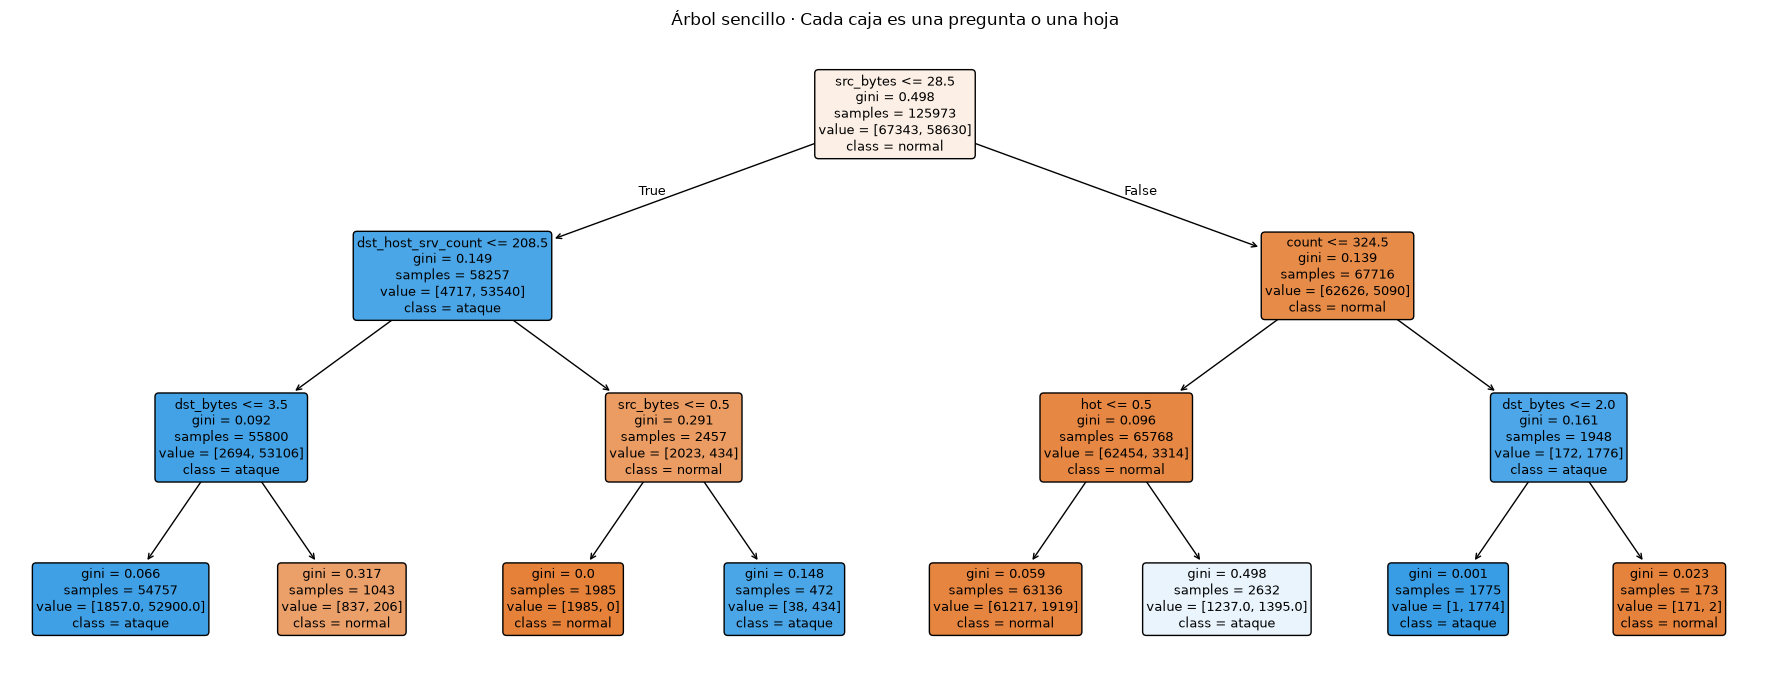

=== B.3 · EVALUACIÓN FINAL DE LOS DOS ÁRBOLES ===


,Modelo,Accuracy test,AP test,Recall ataques test
0,Árbol afinado por validación cruzada,0.790632,0.908921,0.651445
1,Árbol sencillo (profundidad <= 3),0.786950,0.864723,0.651368


In [9]:
print('=== B.2 · REGLAS DEL ÁRBOL SENCILLO (0=NORMAL; 1=ATAQUE) ===')
print(export_text(mini, feature_names=num, decimals=3))
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(
    mini, feature_names=num, class_names=['normal', 'ataque'],
    filled=True, rounded=True, fontsize=9, ax=ax,
)
ax.set_title('Árbol sencillo · Cada caja es una pregunta o una hoja')
fig.tight_layout()
plt.show()

# Tanto el árbol afinado como el sencillo se evalúan en el MISMO test externo.
X_test = te[num]
y_test = te['is_attack']
resultado_arboles = pd.DataFrame([
    {
        'Modelo': 'Árbol afinado por validación cruzada',
        'Accuracy test': accuracy_score(y_test, grid.best_estimator_.predict(X_test)),
        'AP test': average_precision_score(y_test, grid.best_estimator_.predict_proba(X_test)[:, 1]),
        'Recall ataques test': recall_score(y_test, grid.best_estimator_.predict(X_test)),
    },
    {
        'Modelo': 'Árbol sencillo (profundidad <= 3)',
        'Accuracy test': accuracy_score(y_test, mini.predict(X_test)),
        'AP test': average_precision_score(y_test, mini.predict_proba(X_test)[:, 1]),
        'Recall ataques test': recall_score(y_test, mini.predict(X_test)),
    },
])
print('=== B.3 · EVALUACIÓN FINAL DE LOS DOS ÁRBOLES ===')
display(resultado_arboles)

**Interpretación de B.3:** compara la **exactitud** (aciertos globales), el **recall** (ataques que deja escapar) y AP (ordenación de ataques cuando varías el umbral). El árbol sencillo sacrifica detalle para ser explicable; **no está garantizado** que pierda poca exactitud. La diferencia observada se calcula con el dataset de tu ejecución. Que una regla sea comprensible no demuestra que seguirá funcionando en una red moderna.

### Reto avanzado B · Tres reglas y su traducción conceptual a Sigma (resuelto)

**Enunciado original:** escribir las tres reglas más importantes en lenguaje natural, proponer cómo serían como regla Sigma y explicar por qué no sirven directamente en una red moderna.

Una «regla importante» necesita un criterio explícito. Aquí extraeremos los **tres caminos hasta hojas que reúnen más ataques del entrenamiento**. Para cada camino, las condiciones acumuladas deben cumplirse a la vez. Este criterio prioriza **cobertura de ataques de entrenamiento**, no precisión, generalización ni causalidad. Las columnas y umbrales salen del árbol **realmente entrenado**: no son reglas inventadas.

In [10]:
# Reconstruir rutas raíz -> hoja de forma compatible con distintas versiones de sklearn.
arbol_interno = mini.tree_
RAMA_HOJA = -1
rutas_de_hojas = []

def visitar_nodo(indice_nodo, condiciones):
    hijo_izquierdo = int(arbol_interno.children_left[indice_nodo])
    hijo_derecho = int(arbol_interno.children_right[indice_nodo])
    if hijo_izquierdo == RAMA_HOJA:
        # tree_.value suele estar normalizado por nodo en versiones recientes.
        # Para evitar ese detalle, calcularemos después cobertura con datos originales.
        rutas_de_hojas.append((indice_nodo, condiciones))
        return
    nombre_columna = num[arbol_interno.feature[indice_nodo]]
    umbral = float(arbol_interno.threshold[indice_nodo])
    visitar_nodo(hijo_izquierdo, condiciones + [(nombre_columna, '<=', umbral)])
    visitar_nodo(hijo_derecho, condiciones + [(nombre_columna, '>', umbral)])

visitar_nodo(0, [])

# apply() indica a qué hoja llega cada conexión; así la cobertura es inequívoca.
hoja_por_conexion = mini.apply(X)
reglas_candidatas = []
for id_hoja, condiciones in rutas_de_hojas:
    en_hoja = hoja_por_conexion == id_hoja
    ataques_en_hoja = int(y.to_numpy()[en_hoja].sum())
    normales_en_hoja = int(en_hoja.sum()) - ataques_en_hoja
    reglas_candidatas.append((ataques_en_hoja, normales_en_hoja, condiciones))
reglas_candidatas.sort(key=lambda registro: registro[0], reverse=True)

print('=== RETO B · TRES REGLAS QUE CUBREN MÁS ATAQUES EN TRAIN ===')
for numero_regla, (n_ataques, n_normales, condiciones) in enumerate(reglas_candidatas[:3], start=1):
    texto_condiciones = ' Y '.join(
        f'{columna} {operador} {umbral:.4g}'
        for columna, operador, umbral in condiciones
    ) or 'sin condiciones'
    print(f'\nRegla {numero_regla}: SI {texto_condiciones}')
    print(f'  Cobertura de entrenamiento: {n_ataques} ataques y {n_normales} normales.')
    print(f'  Precisión observada en esa hoja: {n_ataques / (n_ataques+n_normales):.1%}')

=== RETO B · TRES REGLAS QUE CUBREN MÁS ATAQUES EN TRAIN ===

Regla 1: SI src_bytes <= 28.5 Y dst_host_srv_count <= 208.5 Y dst_bytes <= 3.5
  Cobertura de entrenamiento: 52900 ataques y 1857 normales.
  Precisión observada en esa hoja: 96.6%

Regla 2: SI src_bytes > 28.5 Y count <= 324.5 Y hot <= 0.5
  Cobertura de entrenamiento: 1919 ataques y 61217 normales.
  Precisión observada en esa hoja: 3.0%

Regla 3: SI src_bytes > 28.5 Y count > 324.5 Y dst_bytes <= 2
  Cobertura de entrenamiento: 1774 ataques y 1 normales.
  Precisión observada en esa hoja: 99.9%


**Respuesta al reto B:** las reglas anteriores son la traducción exacta del árbol a condiciones acumuladas. Para imaginar su equivalente en **Sigma** (formato de reglas para eventos de seguridad), cada campo del flujo tendría que existir en **registros enriquecidos de NetFlow/telemetría**, y cada comparación tendría que convertirse a una selección Sigma compatible con el backend de consultas. Por ejemplo, **solo como esquema conceptual**, si una rama exigiera `count > 20` y `serror_rate <= 0.5`, se expresaría así:

```yaml
# ESQUEMA ILUSTRATIVO: NO es una regla Sigma lista para ejecutar.
logsource:
  category: network_traffic  # Es necesario disponer de eventos agregados con esos campos.
detection:
  seleccion:
    count|gt: 20
    serror_rate|lte: 0.5
  condition: seleccion
```

**Por qué no sirve directamente en una red moderna:** NSL-KDD procede de un benchmark histórico; sus columnas son **características agregadas** que normalmente no existen tal cual en los logs de endpoints o de un firewall, algunas dependen de ventanas y definiciones de tráfico concretas, y los ataques actuales difieren de los ejemplos históricos. Antes de desplegar reglas harían falta: construir equivalencias medibles en la telemetría real, validar tasas de falsos positivos, controlar ventanas temporales y comprobarlas con tráfico contemporáneo. Además, una regla de árbol no es automáticamente una firma de ataque fiable: puede reflejar correlaciones espurias.

---
## Parte C · Random Forest: muchos árboles, una decisión

**Problema:** un árbol individual puede cambiar bastante si cambiamos unas pocas filas de entrenamiento. Un **bosque aleatorio** (*Random Forest*) promedia decisiones de muchos árboles para reducir esa inestabilidad.

**Cómo funciona:** cada árbol se entrena con una **muestra bootstrap** (seleccionar filas *con reemplazo*: una fila puede aparecer dos veces y otra quedar fuera) y, en cada corte, prueba un subconjunto aleatorio de características. Para clasificar, el bosque combina los votos de sus árboles; `predict_proba` promedia sus puntuaciones por clase.

- `n_estimators=200`: construir 200 árboles.
- `min_samples_leaf=2`: cada hoja debe tener al menos dos muestras de entrenamiento.
- `class_weight='balanced_subsample'`: ajusta pesos de las clases en cada muestra bootstrap para mitigar desbalanceos; **no** garantiza mejor rendimiento.
- `oob_score=True`: calcula una estimación de **accuracy OOB** (*out-of-bag*) para cada fila con los árboles que **no** la utilizaron al entrenar. En un bootstrap grande suele quedar fuera una fracción cercana al **36,8 %** de filas en cada árbol: `(1-1/n)^n ≈ e^-1`.

**OOB no equivale a un test externo:** utiliza datos de la misma distribución de entrenamiento. Si el tráfico cambia (como ocurre entre los conjuntos de NSL-KDD), OOB y validación pueden parecer excelentes y test caer. Evita interpretar unas diferencias pequeñas como una ley universal.

=== C.1 · RANDOM FOREST · TRES FORMAS DE MEDIR ===
Filas train interno: 100,778 | validación interna: 25,195 | test externo: 22,544


,Evaluación,Accuracy
0,OOB (train interno),0.997936
1,Validación interna,0.997341
2,Test externo NSL-KDD,0.783135


=== C.2 · EFECTO DEL NÚMERO DE ÁRBOLES (VALIDACIÓN INTERNA) ===


,Número de árboles,Accuracy de validación
0,1,0.991625
1,5,0.996944
2,25,0.996944
3,100,0.997142


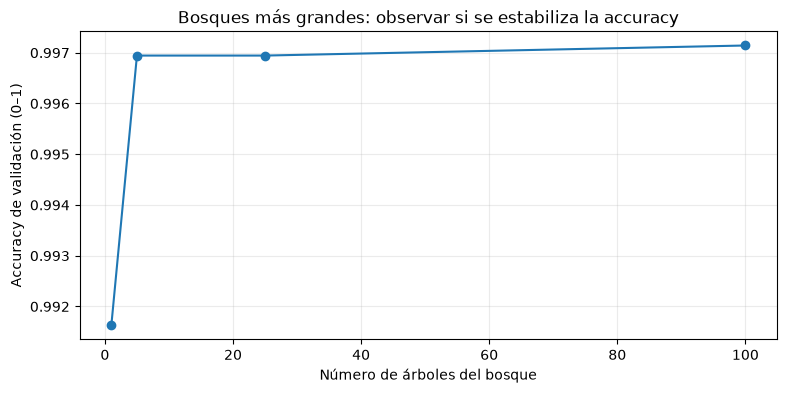

In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

# Dividir SOLO el train de NSL-KDD en entrenamiento interno y validación.
# stratify conserva aproximadamente el porcentaje de ataques de cada parte.
Xtr, Xval, ytr, yval = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=0
)
rf = RandomForestClassifier(
    n_estimators=200, min_samples_leaf=2,
    oob_score=True, class_weight='balanced_subsample',
    n_jobs=-1, random_state=0,
).fit(Xtr, ytr)

print('=== C.1 · RANDOM FOREST · TRES FORMAS DE MEDIR ===')
print(f'Filas train interno: {len(Xtr):,} | validación interna: {len(Xval):,} | test externo: {len(te):,}')
medidas_bosque = pd.DataFrame([
    {'Evaluación': 'OOB (train interno)', 'Accuracy': rf.oob_score_},
    {'Evaluación': 'Validación interna', 'Accuracy': rf.score(Xval, yval)},
    {'Evaluación': 'Test externo NSL-KDD', 'Accuracy': rf.score(te[num], te['is_attack'])},
])
display(medidas_bosque)

# Experimento original: entrenar bosques de distintos tamaños y medir validation accuracy.
# Atención: estos bosques NO tienen todos los hiperparámetros del rf principal
# (se mantienen los parámetros originales del experimento para no cambiar resultados).
comparacion_tamanos = []
for cantidad_arboles in [1, 5, 25, 100]:
    bosque_experimento = RandomForestClassifier(
        n_estimators=cantidad_arboles, min_samples_leaf=2,
        n_jobs=-1, random_state=0,
    ).fit(Xtr, ytr)
    comparacion_tamanos.append({
        'Número de árboles': cantidad_arboles,
        'Accuracy de validación': bosque_experimento.score(Xval, yval),
    })
tabla_tamanos = pd.DataFrame(comparacion_tamanos)
print('=== C.2 · EFECTO DEL NÚMERO DE ÁRBOLES (VALIDACIÓN INTERNA) ===')
display(tabla_tamanos)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(tabla_tamanos['Número de árboles'], tabla_tamanos['Accuracy de validación'], 'o-')
ax.set(xlabel='Número de árboles del bosque', ylabel='Accuracy de validación (0–1)',
       title='Bosques más grandes: observar si se estabiliza la accuracy')
ax.grid(alpha=0.25)
plt.show()

**Cómo leer C.1:** OOB y validación reflejan generalización **dentro de la distribución de train**; test mide las conexiones apartadas por NSL-KDD. Compara los valores observados, sin exigir que sean exactamente iguales. **Cómo leer C.2:** el eje X es el número de árboles y el eje Y la fracción de aciertos. Al agregar árboles suele reducirse la variabilidad del modelo, pero **no está garantizado un aumento monótono de accuracy**: importa la correlación entre árboles, los hiperparámetros y los datos. El experimento con 1, 5, 25 y 100 árboles utiliza los ajustes originales, que **no son idénticos** al bosque principal de 200 árboles (sin los pesos `balanced_subsample` en los bosques comparativos).

### C.3 · Dos significados distintos de «importancia»

**Importancia por impureza (`feature_importances_`):** suma y normaliza cuánto redujo la mezcla cada característica a lo largo de los cortes del bosque. Puede favorecer variables continuas o con muchas posibles divisiones y características correlacionadas.

**Importancia por permutación:** toma una característica y **desordena sus valores entre conexiones** de un conjunto de validación, rompiendo su relación con la etiqueta; mide cuánto empeora el modelo. Aquí la métrica perturbada es **AP**, no accuracy. Ejemplo: AP inicial 0,90, AP tras permutar una columna 0,72 → importancia aproximada 0,18. Una columna con importancia casi 0 puede ser redundante con otra, no necesariamente inútil.

**No compares numéricamente los ejes como si fueran la misma unidad.** Son dos métodos de medición diferentes.

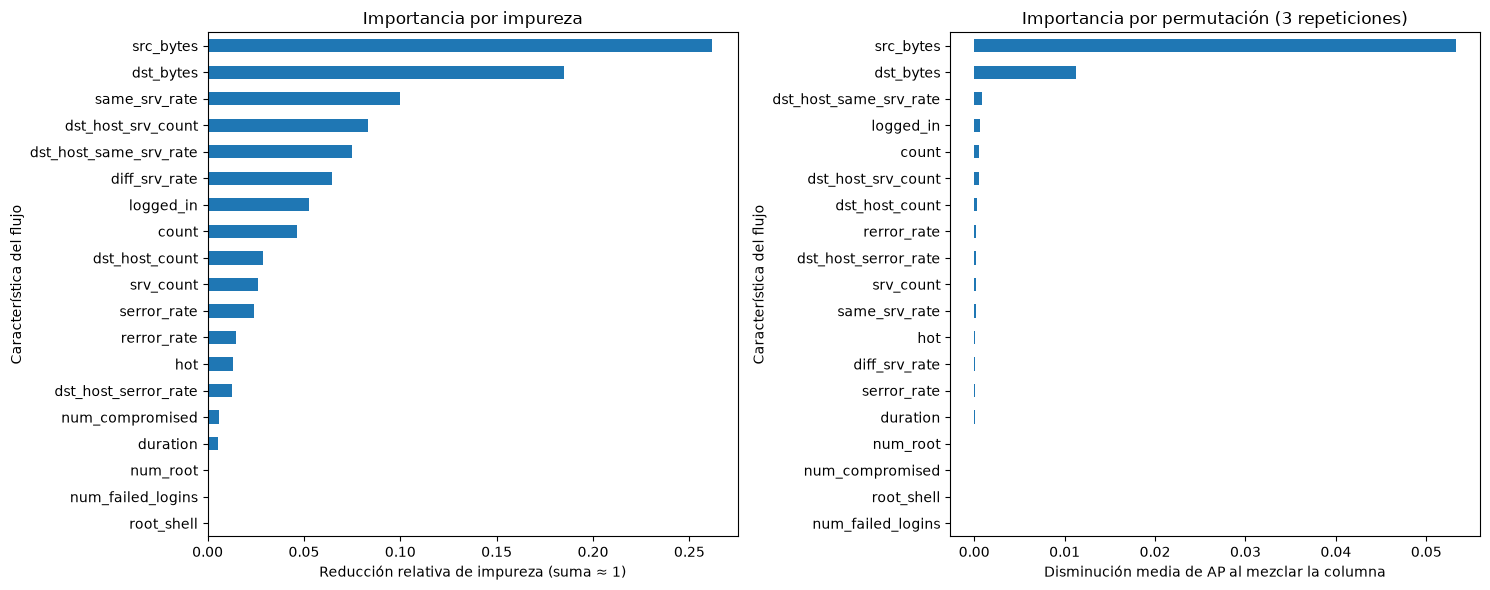

=== C.3 · CARACTERÍSTICAS MÁS IMPORTANTES SEGÚN CADA MÉTODO ===


,Por impureza,Por permutación AP
0,src_bytes,src_bytes
1,dst_bytes,dst_bytes
2,same_srv_rate,dst_host_same_srv_rate
3,dst_host_srv_count,logged_in
4,dst_host_same_srv_rate,count


In [12]:
# Reutilizar un máximo de 5.000 filas de validación; no alterar el entrenamiento.
# El mínimo permite probar el notebook también con un train local más pequeño.
submuestra_validacion = Xval.sample(min(5000, len(Xval)), random_state=0)
etiquetas_submuestra = yval.loc[submuestra_validacion.index]
importancia_permutada = permutation_importance(
    rf, submuestra_validacion, etiquetas_submuestra,
    n_repeats=3, random_state=0, n_jobs=-1,
    scoring='average_precision',
)
importancias_impureza = pd.Series(rf.feature_importances_, index=num).sort_values()
importancias_permutacion = pd.Series(
    importancia_permutada.importances_mean, index=num
).sort_values()

fig, ejes = plt.subplots(1, 2, figsize=(15, 6))
importancias_impureza.plot.barh(ax=ejes[0])
ejes[0].set(xlabel='Reducción relativa de impureza (suma ≈ 1)',
             ylabel='Característica del flujo', title='Importancia por impureza')
importancias_permutacion.plot.barh(ax=ejes[1])
ejes[1].set(xlabel='Disminución media de AP al mezclar la columna',
             ylabel='Característica del flujo', title='Importancia por permutación (3 repeticiones)')
plt.tight_layout()
plt.show()
print('=== C.3 · CARACTERÍSTICAS MÁS IMPORTANTES SEGÚN CADA MÉTODO ===')
display(pd.DataFrame({
    'Por impureza': importancias_impureza.sort_values(ascending=False).head(5).index,
    'Por permutación AP': importancias_permutacion.sort_values(ascending=False).head(5).index,
}))

**Interpretación de C.3:** si los rankings no coinciden, no hay contradicción: el primero resume cómo **se construyó** el modelo y el segundo mide cuánto **depende** de cada columna para predecir en la muestra de validación elegida. La permutación puede producir resultados pequeños o negativos por azar y por características redundantes. La importancia estadística **no prueba causalidad** ni demuestra que una señal no pueda manipularse.

### Reto avanzado C · Recall por tipo de ataque y varianza correlacionada (resuelto)

**Enunciado original:** medir el recall por categoría `dos`, `probe`, `r2l` y `u2r` usando `add_category`; y calcular la varianza de la media de **100 árboles**, cada uno con varianza `σ² = 1` y correlación entre pares `ρ = 0,3`:

\[\operatorname{Var}(\bar T_B)=\rho\sigma^2+(1-\rho)\frac{\sigma^2}{B}.\]

El **recall de la categoría** se calcula solo entre los **ataques reales de esa categoría**: conexiones clasificadas como ataque ÷ total de conexiones de ese tipo. Para `normal` no tiene sentido llamarlo recall de ataque; en su lugar mostramos **tasa de falsos positivos** (normales acusados de ataque ÷ normales). Si una categoría contiene muy pocos ejemplos, el porcentaje será inestable y debe leerse junto a su cantidad.

In [13]:
# add_category añade 'category' según las etiquetas originales de NSL-KDD.
test_categorizado = add_category(te.copy())
predicciones_rf_test = rf.predict(te[num])
analisis_categorias = []
for categoria in ['normal', 'dos', 'probe', 'r2l', 'u2r']:
    en_categoria = test_categorizado['category'].eq(categoria).to_numpy()
    cantidad = int(en_categoria.sum())
    # La clase positiva del RF siempre significa 'ataque', aunque su familia cambie.
    alertas = int(predicciones_rf_test[en_categoria].sum()) if cantidad else 0
    analisis_categorias.append({
        'Categoría real': categoria,
        'Conexiones': cantidad,
        'Detectadas como ataque': alertas,
        'No detectadas como ataque': cantidad - alertas,
        'Métrica': 'FPR: normales alertados' if categoria == 'normal' else 'Recall: ataques detectados',
        'Tasa': alertas / cantidad if cantidad else np.nan,
    })
print('=== RETO C.1 · RESULTADOS DEL BOSQUE POR CATEGORÍA NSL-KDD ===')
display(pd.DataFrame(analisis_categorias))

# Descomponer la fórmula del enunciado para mostrar por qué existe un límite.
varianza_individual = 1.0
correlacion_arboles = 0.3
varianza_media_100 = (
    correlacion_arboles * varianza_individual
    + (1 - correlacion_arboles) * varianza_individual / 100
)
print('\n=== RETO C.2 · VARIANZA TEÓRICA DE UNA MEDIA DE ÁRBOLES ===')
print(f'Varianza por árbol (σ²): {varianza_individual:.1f}')
print(f'Correlación entre árboles (ρ): {correlacion_arboles:.1f}')
print(f'Varianza del promedio de 100 árboles: {varianza_media_100:.3f}')
print(f'Límite si B tiende a infinito: ρ·σ² = {correlacion_arboles*varianza_individual:.3f}')

=== RETO C.1 · RESULTADOS DEL BOSQUE POR CATEGORÍA NSL-KDD ===


,Categoría real,Conexiones,Detectadas como ataque,No detectadas como ataque,Métrica,Tasa
0,normal,9711,252,9459,FPR: normales alertados,0.025950
1,dos,7458,5907,1551,Recall: ataques detectados,0.792035
2,probe,2421,1968,453,Recall: ataques detectados,0.812887
3,r2l,2887,316,2571,Recall: ataques detectados,0.109456
4,u2r,67,5,62,Recall: ataques detectados,0.074627



=== RETO C.2 · VARIANZA TEÓRICA DE UNA MEDIA DE ÁRBOLES ===
Varianza por árbol (σ²): 1.0
Correlación entre árboles (ρ): 0.3
Varianza del promedio de 100 árboles: 0.307
Límite si B tiende a infinito: ρ·σ² = 0.300


**Respuesta al reto C:** con `B=100`, el término que **no desaparece** es `ρσ² = 0,3`; el que sí se reduce es `0,7/100 = 0,007`. Total: **0,307**. Incluso con infinitos árboles, el límite será **0,3** mientras sus errores permanezcan correlacionados. Intuición: cien personas que copian la misma respuesta pueden equivocarse juntas; añadir más copias no elimina el error compartido. Esta fórmula describe un **promedio de variables correlacionadas bajo supuestos simplificados**, no es la varianza empírica medida en nuestro bosque.

---
## Parte D · Boosting y parada temprana

**Problema:** un bosque combina árboles entrenados relativamente **en paralelo** para reducir la inestabilidad. ¿Y si los árboles se construyen **secuencialmente**, haciendo que cada uno corrija lo que el conjunto anterior aún predice mal?

El **gradient boosting** añade árboles pequeños uno tras otro y ajusta sus contribuciones para reducir una función de pérdida. Se compara con un profesor que devuelve un ejercicio corregido: el siguiente intento se centra en errores que todavía persisten. La analogía tiene un límite: el método optimiza una pérdida matemática, no entiende por sí mismo el significado de una amenaza.

- `HistGradientBoostingClassifier` (HistGB): versión eficiente de scikit-learn que agrupa valores numéricos en intervalos (*bins*) y construye árboles con esos valores agrupados.
- `XGBClassifier` (XGBoost): implementación de boosting con regularización y técnicas adicionales de muestreo.
- `learning_rate=0.1`: reduce cuánto aporta cada nuevo árbol. Una tasa menor suele requerir más iteraciones; una mayor puede converger rápido pero pasarse de largo.
- `subsample=0.8` y `colsample_bytree=0.8`: XGBoost utiliza aproximadamente el 80 % de filas por iteración y el 80 % de columnas por árbol, introduciendo aleatoriedad.
- **Parada temprana:** detiene el aprendizaje si la pérdida de validación no mejora durante cierto número de rondas, para evitar entrenar mucho más allá del mejor punto.

**`log-loss`** penaliza probabilidades erróneas y confiadas: si una conexión es realmente un ataque (`y=1`), predecir `0,99` tiene pérdida `−ln(0,99) ≈ 0,01`, pero predecir `0,01` tiene `−ln(0,01) ≈ 4,61`. **Menor log-loss es mejor**. **AP** es otra métrica: ordena conexiones según su puntuación de ataque y resume precisión–recall. No confundas log-loss, AP y accuracy.

**Diferencia importante entre modelos en esta práctica:** HistGB reserva internamente un 15 % de `Xtr` para validar; XGBoost recibe explícitamente `Xval`/`yval`. Sus rondas y tiempos no son perfectamente comparables: usan implementaciones, conjuntos de parada y criterios diferentes.

In [14]:
from sklearn.ensemble import HistGradientBoostingClassifier
from xgboost import XGBClassifier
import time

# Configuraciones originales de la práctica: dos modelos que aprenden secuencialmente.
modelos_boosting = {
    'HistGB': HistGradientBoostingClassifier(
        max_iter=500, early_stopping=True,
        validation_fraction=0.15, n_iter_no_change=20, random_state=0,
    ),
    'XGBoost': XGBClassifier(
        n_estimators=1000, learning_rate=0.1, max_depth=6,
        subsample=0.8, colsample_bytree=0.8,
        eval_metric='logloss', early_stopping_rounds=30,
        n_jobs=-1, random_state=0,
    ),
}
filas = []
for nombre_modelo, modelo in modelos_boosting.items():
    # Medir SOLO .fit(): el tiempo de predicción no se mezcla con el de entrenamiento.
    inicio_entrenamiento = time.perf_counter()
    if nombre_modelo == 'XGBoost':
        modelo.fit(Xtr, ytr, eval_set=[(Xval, yval)], verbose=False)
        # best_iteration comienza en 0; +1 lo transforma en cantidad de rondas.
        rondas_ejecutadas_hasta_mejor = modelo.best_iteration + 1
        xgb = modelo
    else:
        modelo.fit(Xtr, ytr)
        rondas_ejecutadas_hasta_mejor = modelo.n_iter_
    segundos_entrenamiento = time.perf_counter() - inicio_entrenamiento

    # Probabilidades estimadas de clase 1 (ataque) en el test EXTERNO.
    probabilidades_ataque = modelo.predict_proba(te[num])[:, 1]
    filas.append({
        'Modelo': nombre_modelo,
        'Árboles / rondas': rondas_ejecutadas_hasta_mejor,
        'Tiempo fit (s)': segundos_entrenamiento,
        'AP test': average_precision_score(te['is_attack'], probabilidades_ataque),
        'Accuracy test': ((probabilidades_ataque > 0.5) == te['is_attack']).mean(),
    })

# Comparación con el Random Forest YA entrenado en la parte C.
# No inventamos su tiempo de entrenamiento, que no se había medido al hacer .fit().
probabilidades_rf = rf.predict_proba(te[num])[:, 1]
filas.append({
    'Modelo': 'RandomForest', 'Árboles / rondas': 200, 'Tiempo fit (s)': np.nan,
    'AP test': average_precision_score(te['is_attack'], probabilidades_rf),
    'Accuracy test': rf.score(te[num], te['is_attack']),
})
tabla_modelos = pd.DataFrame(filas)
print('=== D.1 · RANDOM FOREST VS BOOSTING · MISMO TEST EXTERNO ===')
print('AP resume la curva precisión–recall; accuracy mide aciertos con el umbral de cada modelo.')
print('Los tiempos dependen de CPU, bibliotecas y carga del sistema; RF no se cronometró.')
display(tabla_modelos)

=== D.1 · RANDOM FOREST VS BOOSTING · MISMO TEST EXTERNO ===
AP resume la curva precisión–recall; accuracy mide aciertos con el umbral de cada modelo.
Los tiempos dependen de CPU, bibliotecas y carga del sistema; RF no se cronometró.


,Modelo,Árboles / rondas,Tiempo fit (s),AP test,Accuracy test
0,HistGB,238,1.042913,0.972098,0.787083
1,XGBoost,340,1.948780,0.971143,0.795067
2,RandomForest,200,NaN,0.972668,0.783135


### D.2 · ¿Cuándo se detuvo XGBoost?

XGBoost registra el **log-loss de validación por ronda**. El eje horizontal muestra el número de rondas completadas y el vertical la pérdida. La línea roja marca la ronda con la **mejor pérdida de validación** (`best_iteration`, indexada desde cero dentro de la biblioteca). Por eso en pantalla sumamos uno al número de la ronda. El entrenamiento **puede continuar 30 rondas adicionales** buscando mejora antes de parar; «ronda mejor» y «última ronda ejecutada» no tienen por qué coincidir.

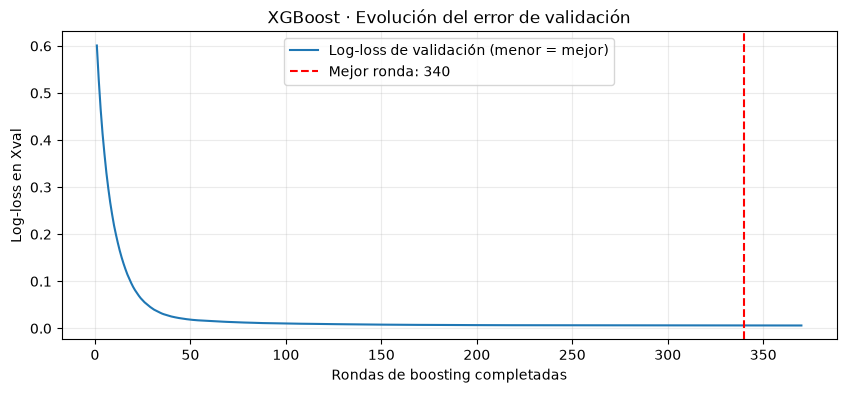

=== D.2 · PARADA TEMPRANA ===
Mejor ronda (contada desde 1): 340
Última ronda cuya pérdida se registró: 370
Mejor log-loss registrado: 0.00603


In [15]:
perdidas_validacion = xgb.evals_result()['validation_0']['logloss']
indice_mejor_ronda = xgb.best_iteration
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(np.arange(1, len(perdidas_validacion) + 1), perdidas_validacion,
        label='Log-loss de validación (menor = mejor)')
ax.axvline(indice_mejor_ronda + 1, color='red', linestyle='--',
           label=f'Mejor ronda: {indice_mejor_ronda + 1}')
ax.set(xlabel='Rondas de boosting completadas', ylabel='Log-loss en Xval',
       title='XGBoost · Evolución del error de validación')
ax.grid(alpha=0.25)
ax.legend()
plt.show()
print('=== D.2 · PARADA TEMPRANA ===')
print(f'Mejor ronda (contada desde 1): {indice_mejor_ronda + 1}')
print(f'Última ronda cuya pérdida se registró: {len(perdidas_validacion)}')
print(f'Mejor log-loss registrado: {perdidas_validacion[indice_mejor_ronda]:.5f}')

**Interpretación de D:** el modelo con más rondas no tiene por qué ser mejor. Lo relevante es la **AP de test**, la exactitud y, para un IDS, la **precisión, el recall y la tasa de alertas falsas bajo un umbral operativo**. La tabla de D.1 es una comparación descriptiva con una sola separación de datos; no identifica por sí sola «el mejor modelo universal». Además, un test histórico no garantiza resistencia a cambios de distribución.

### Reto avanzado D · Tasa de aprendizaje, clase U2R y decisión de despliegue (resuelto)

**Enunciado original:** comparar `learning_rate = 0,01` y `0,5`, medir rondas y rendimiento; probar `scale_pos_weight` en U2R contra el resto; elegir un modelo para IDS y justificarlo.

**D.3 · Learning rate:** conservamos los demás hiperparámetros originales de XGBoost y variamos solo la tasa. **Usamos `Xval` para comparar y NO el test**: si escogiéramos la tasa por AP de test, contaminaríamos esa evaluación final. La siguiente celda vuelve a entrenar dos modelos; es más costosa que las anteriores.

In [16]:
comparacion_tasas = []
for tasa_aprendizaje in [0.01, 0.5]:
    candidato = XGBClassifier(
        n_estimators=1000, learning_rate=tasa_aprendizaje,
        max_depth=6, subsample=0.8, colsample_bytree=0.8,
        eval_metric='logloss', early_stopping_rounds=30,
        n_jobs=-1, random_state=0,
    )
    inicio = time.perf_counter()
    candidato.fit(Xtr, ytr, eval_set=[(Xval, yval)], verbose=False)
    duracion = time.perf_counter() - inicio
    probabilidades_val = candidato.predict_proba(Xval)[:, 1]
    comparacion_tasas.append({
        'Learning rate': tasa_aprendizaje,
        'Mejor ronda (desde 1)': candidato.best_iteration + 1,
        'Rondas ejecutadas': len(candidato.evals_result()['validation_0']['logloss']),
        'AP validación': average_precision_score(yval, probabilidades_val),
        'Accuracy validación': accuracy_score(yval, probabilidades_val > 0.5),
        'Tiempo fit (s)': duracion,
    })
print('=== RETO D.3 · INFLUENCIA DE LEARNING RATE (MISMA VALIDACIÓN) ===')
print('La comparación es entre tasas 0,01 y 0,5; el modelo principal usó 0,1.')
display(pd.DataFrame(comparacion_tasas))

=== RETO D.3 · INFLUENCIA DE LEARNING RATE (MISMA VALIDACIÓN) ===
La comparación es entre tasas 0,01 y 0,5; el modelo principal usó 0,1.


,Learning rate,Mejor ronda (desde 1),Rondas ejecutadas,AP validación,Accuracy validación,Tiempo fit (s)
0,0.01,1000,1000,0.999909,0.997301,4.079228
1,0.50,74,104,0.999950,0.997817,0.597160


**Cómo interpretar D.3:** `0,01` suele necesitar **más rondas** para avanzar una distancia similar, mientras que `0,5` da pasos mayores y puede detenerse antes o empeorar por sobreajuste o inestabilidad. Son **tendencias**, no cifras garantizadas: observa «Mejor ronda», «Rondas ejecutadas» y «AP validación» para responder con los **datos reales** de tu ejecución. Un máximo de 1.000 árboles puede limitar especialmente la tasa más pequeña.

**D.4 · U2R frente al resto:** *User to Root* (U2R) es una categoría específica de ataque poco frecuente en NSL-KDD. Cambiamos **la pregunta que aprende el modelo**: ahora `1 = U2R`; `0 = normal o cualquier otro ataque`. No debemos mezclar la etiqueta binaria general de los apartados anteriores con esta nueva etiqueta. `scale_pos_weight = n_negativos/n_positivos` aumenta el peso de los errores sobre la clase rara. **Más peso no garantiza mejor recall o menos falsos positivos**; por eso se comparan dos modelos sobre la misma validación, sin test.

In [17]:
# Crear una NUEVA etiqueta solo para el reto, sin alterar 'is_attack' ni el RF anterior.
entrenamiento_con_categoria = add_category(tr.copy())
etiqueta_u2r = (entrenamiento_con_categoria['category'] == 'u2r').astype(int)
X_u2r_train, X_u2r_val, y_u2r_train, y_u2r_val = train_test_split(
    tr[num], etiqueta_u2r, test_size=0.2, stratify=etiqueta_u2r, random_state=0
)
positivos_u2r = int(y_u2r_train.sum())
negativos_u2r = len(y_u2r_train) - positivos_u2r
peso_u2r = negativos_u2r / positivos_u2r  # Razón de desequilibrio del train interno.

resultados_u2r = []
for nombre, peso in [('Sin ponderar', 1.0), ('Ponderado', peso_u2r)]:
    detector_u2r = XGBClassifier(
        n_estimators=300, learning_rate=0.1, max_depth=6,
        subsample=0.8, colsample_bytree=0.8,
        eval_metric='logloss', early_stopping_rounds=30,
        scale_pos_weight=peso, n_jobs=-1, random_state=0,
    )
    detector_u2r.fit(
        X_u2r_train, y_u2r_train,
        eval_set=[(X_u2r_val, y_u2r_val)], verbose=False,
    )
    prob_u2r = detector_u2r.predict_proba(X_u2r_val)[:, 1]
    pred_u2r = (prob_u2r > 0.5).astype(int)
    resultados_u2r.append({
        'Modelo': nombre,
        'Peso clase U2R': peso,
        'AP val': average_precision_score(y_u2r_val, prob_u2r),
        'Recall U2R val': recall_score(y_u2r_val, pred_u2r, zero_division=0),
        'Precisión U2R val': precision_score(y_u2r_val, pred_u2r, zero_division=0),
        'Alertas U2R en validación': int(pred_u2r.sum()),
    })
print('=== RETO D.4 · U2R (1) FRENTE A RESTO (0) ===')
print(f'Entrenamiento: {positivos_u2r} positivos U2R y {negativos_u2r} negativos')
print(f'Validación: {int(y_u2r_val.sum())} positivos U2R de {len(y_u2r_val)} conexiones')
print('La clase es extremadamente escasa: pequeñas diferencias en aciertos cambian mucho el recall.')
display(pd.DataFrame(resultados_u2r))

=== RETO D.4 · U2R (1) FRENTE A RESTO (0) ===
Entrenamiento: 42 positivos U2R y 100736 negativos
Validación: 10 positivos U2R de 25195 conexiones
La clase es extremadamente escasa: pequeñas diferencias en aciertos cambian mucho el recall.


,Modelo,Peso clase U2R,AP val,Recall U2R val,Precisión U2R val,Alertas U2R en validación
0,Sin ponderar,1.00000,0.79859,0.5,1.0,5
1,Ponderado,2398.47619,0.80228,0.8,0.8,10


**Respuesta a D.4 y despliegue:** si el modelo ponderado eleva el recall, revisa **cuántas alertas falsas adicionales** provoca y cómo cambia la AP. Con muy pocas muestras U2R, un pequeño cambio puede ser fruto del azar, no una mejora estable. Para un **IDS** propondría **pilotar el modelo que consiga buen recall con una carga de falsos positivos asumible y tiempos de inferencia compatibles con el caudal**. Entre resultados parecidos, preferiría el más simple de mantener. No desplegaría ninguno basándome solo en NSL-KDD: exigiría datos actuales, evaluación temporal, latencia, volumen real de alertas, deriva del tráfico y monitorización tras el despliegue. El resultado específico para tu ejecución está en la tabla D.1; no puede deducirse por anticipado que XGBoost o el bosque será superior.

---
## Parte E · Atajos: por qué una accuracy casi perfecta puede engañar

**Problema:** el modelo puede aprender una **huella incidental de la herramienta** que generó los ataques en el laboratorio, en vez de patrones que sigan presentes al cambiar de atacante, herramienta o infraestructura.

El curso genera **60.000 flujos sintéticos** con etiquetas `BENIGN`/`DDoS`, unos de tráfico normal y otros de dos episodios simulados de ataque. El primero incluye una huella reconocible (`Init_Win_bytes_forward = 8192` y puerto de destino `80`); el segundo usa valores diferentes. **No procede de capturas reales de CICIDS2017:** el generador solo imita nombres de columnas y características de esos flujos.

1. **División aleatoria:** mezcla ambos episodios entre entrenamiento y evaluación. Si existe una huella, el modelo puede verla en ambos lados y rendir artificialmente bien.
2. **División temporal:** entrena con flujos anteriores a las **12:30 del 7 de julio de 2017** y evalúa flujos posteriores. Obliga a predecir el segundo episodio, cuya herramienta dejó otras señales.

La exactitud temporal puede seguir alta si hay muchos normales. Por eso mediremos **recall de ataque** explícitamente, usando `recall_score`. **Corrección del original:** la expresión `cantidad_de_predicciones_positivas / cantidad_de_ataques_reales` **NO es recall**, ya que cuenta falsos positivos entre las predicciones; puede incluso superar 1. La expresión correcta es `TP / (TP + FN)`, donde TP son conexiones con etiqueta real de ataque **y** predicción de ataque.

In [18]:
# Generar flujos ARTIFICIALES reproducibles: misma semilla y mismos parámetros.
w = generar_flujos(seed=1, cambio_herramienta=True)
w.columns = w.columns.str.strip()

# Limpieza de valores imposibles, ausentes y registros exactamente duplicados.
# Desde aquí usamos un DataFrame nuevo 'w', no sobrescribimos NSL-KDD 'tr'/'te'.
filas_antes_limpieza = len(w)
w = w.replace([np.inf, -np.inf], np.nan).dropna().drop_duplicates().reset_index(drop=True)
w['y'] = (w['Label'] != 'BENIGN').astype(int)

# No usar la etiqueta real, el timestamp ni la nueva y como predictores.
cols = [columna for columna in w.columns if columna not in ('Label', 'y', 'Timestamp')]

# 1) División aleatoria estratificada: mezcla épocas y herramientas.
Xa, Xb, ya, yb = train_test_split(
    w[cols], w['y'], test_size=0.3, stratify=w['y'], random_state=0
)
rf1 = RandomForestClassifier(100, n_jobs=-1, random_state=0).fit(Xa, ya)
pred_aleatorio = rf1.predict(Xb)

# 2) División temporal: pasado para aprender, futuro para evaluar.
corte = pd.Timestamp('2017-07-07 12:30')
ant = w[w['Timestamp'] < corte]
des = w[w['Timestamp'] >= corte]
rf2 = RandomForestClassifier(100, n_jobs=-1, random_state=0).fit(ant[cols], ant['y'])
pred_temporal = rf2.predict(des[cols])

# Comparar siempre métricas del mismo tipo: accuracy y recall en cada partición.
resultados_atributos = pd.DataFrame([
    {
        'Evaluación': 'Aleatoria (mezcla episodios)',
        'Ejemplos evaluados': len(yb),
        'Ataques reales': int(yb.sum()),
        'Accuracy': accuracy_score(yb, pred_aleatorio),
        'Recall de ataque': recall_score(yb, pred_aleatorio, zero_division=0),
        'Precisión de alertas': precision_score(yb, pred_aleatorio, zero_division=0),
    },
    {
        'Evaluación': 'Temporal (entrenar antes de 12:30)',
        'Ejemplos evaluados': len(des),
        'Ataques reales': int(des['y'].sum()),
        'Accuracy': accuracy_score(des['y'], pred_temporal),
        'Recall de ataque': recall_score(des['y'], pred_temporal, zero_division=0),
        'Precisión de alertas': precision_score(des['y'], pred_temporal, zero_division=0),
    },
])
print('=== E.1 · FLUJOS SINTÉTICOS Y LIMPIEZA ===')
print(f'Filas antes: {filas_antes_limpieza:,} | después: {len(w):,} | columnas de entrada: {len(cols)}')
print(f'Entrenamiento temporal: {len(ant):,} flujos | evaluación temporal: {len(des):,} flujos')
print('\n=== E.2 · MISMO ALGORITMO, DISTINTA FORMA DE EVALUAR ===')
display(resultados_atributos)
print('\n=== E.3 · CINCO VARIABLES MÁS UTILIZADAS EN EL BOSQUE ALEATORIO ===')
display(pd.DataFrame({
    'Característica': pd.Series(rf1.feature_importances_, index=cols).nlargest(5).index,
    'Importancia por impureza': pd.Series(rf1.feature_importances_, index=cols).nlargest(5).values,
}))

=== E.1 · FLUJOS SINTÉTICOS Y LIMPIEZA ===
Filas antes: 60,600 | después: 59,045 | columnas de entrada: 15
Entrenamiento temporal: 26,782 flujos | evaluación temporal: 32,263 flujos

=== E.2 · MISMO ALGORITMO, DISTINTA FORMA DE EVALUAR ===


,Evaluación,Ejemplos evaluados,Ataques reales,Accuracy,Recall de ataque,Precisión de alertas
0,Aleatoria (mezcla episodios),17714,4491,0.985379,0.969272,0.972955
1,Temporal (entrenar antes de 12:30),32263,7381,0.769643,0.000000,0.000000



=== E.3 · CINCO VARIABLES MÁS UTILIZADAS EN EL BOSQUE ALEATORIO ===


,Característica,Importancia por impureza
0,Bwd Packet Length Mean,0.154938
1,Fwd Packet Length Mean,0.136905
2,Total Backward Packets,0.125692
3,Avg Fwd Segment Size,0.117352
4,Total Length of Fwd Packets,0.112949


**Cómo interpretar E.2:** si la división aleatoria muestra casi todos los ataques detectados y la temporal pierde muchos, tenemos **evidencia de falta de generalización entre episodios**, compatible con la hipótesis de que el modelo aprendió una huella de herramienta. Comprueba **recall**, no solo exactitud. La tabla E.3 muestra qué características favorecieron cortes en el bosque aleatorio; que una huella esté arriba **sugiere una asociación**, pero **no demuestra por sí sola** la causa de la caída. La ablación siguiente investiga precisamente ese papel.

> **Observación frente a hipótesis:** «el recall temporal es X %» es una observación calculada; «el bosque memorizó la herramienta» es una hipótesis interpretativa. La comparación aleatoria/temporal y el experimento de ablación la ponen a prueba, pero puede haber también otros cambios entre episodios.

### Reto avanzado E · Ablación de las huellas (resuelto)

**Enunciado original:** retirar `Destination Port` e `Init_Win_bytes_forward`, repetir las dos divisiones, identificar las señales de comportamiento que quedan y resumir el riesgo de publicar un 99,9 % sin esta comprobación.

**Ablación** significa quitar deliberadamente una parte de la información y repetir **el mismo experimento**, para observar cómo cambia el resultado. Así aislamos el efecto de esas dos columnas: no cambiamos filas, etiquetas, criterios de partición ni hiperparámetros. La eliminación se aplica en ambos conjuntos antes de entrenar. Si mejora el recall temporal pero baja accuracy aleatoria, sería coherente con una huella que ayudaba artificialmente en la evaluación mezclada.

In [20]:
columnas_huella = ['Destination Port', 'Init_Win_bytes_forward']
columnas_sin_huella = [columna for columna in cols if columna not in columnas_huella]
assert all(columna not in columnas_sin_huella for columna in columnas_huella)

# Repetir la MISMA división aleatoria sobre exactamente las mismas filas, sin huellas.
rf1_sin_huella = RandomForestClassifier(100, n_jobs=-1, random_state=0)
rf1_sin_huella.fit(Xa[columnas_sin_huella], ya)
pred_aleatorio_sin_huella = rf1_sin_huella.predict(Xb[columnas_sin_huella])

# Repetir la MISMA división temporal sobre exactamente los mismos episodios, sin huellas.
rf2_sin_huella = RandomForestClassifier(100, n_jobs=-1, random_state=0)
rf2_sin_huella.fit(ant[columnas_sin_huella], ant['y'])
pred_temporal_sin_huella = rf2_sin_huella.predict(des[columnas_sin_huella])

comparacion_ablacion = pd.DataFrame([
    {'Partición': 'Aleatoria', 'Columnas': 'Todas',
     'Accuracy': accuracy_score(yb, pred_aleatorio),
     'Recall': recall_score(yb, pred_aleatorio, zero_division=0)},
    {'Partición': 'Aleatoria', 'Columnas': 'Sin 2 huellas',
     'Accuracy': accuracy_score(yb, pred_aleatorio_sin_huella),
     'Recall': recall_score(yb, pred_aleatorio_sin_huella, zero_division=0)},
    {'Partición': 'Temporal', 'Columnas': 'Todas',
     'Accuracy': accuracy_score(des['y'], pred_temporal),
     'Recall': recall_score(des['y'], pred_temporal, zero_division=0)},
    {'Partición': 'Temporal', 'Columnas': 'Sin 2 huellas',
     'Accuracy': accuracy_score(des['y'], pred_temporal_sin_huella),
     'Recall': recall_score(des['y'], pred_temporal_sin_huella, zero_division=0)},
])
print('=== RETO E · ABLACIÓN DE DOS HUELLAS DE LABORATORIO ===')
print('Columnas eliminadas:', ', '.join(columnas_huella))
print(f'Columnas restantes: {len(columnas_sin_huella)} de {len(cols)}')
display(comparacion_ablacion)

print('\n=== SEÑALES RESTANTES CON MAYOR IMPORTANCIA EN LA DIVISIÓN TEMPORAL ===')
importancia_sin_huella = pd.Series(
    rf2_sin_huella.feature_importances_, index=columnas_sin_huella
).sort_values(ascending=False)
display(importancia_sin_huella.head(8).rename_axis('Característica').rename(
    'Importancia por impureza').to_frame())

=== RETO E · ABLACIÓN DE DOS HUELLAS DE LABORATORIO ===
Columnas eliminadas: Destination Port, Init_Win_bytes_forward
Columnas restantes: 13 de 15


,Partición,Columnas,Accuracy,Recall
0,Aleatoria,Todas,0.985379,0.969272
1,Aleatoria,Sin 2 huellas,0.976233,0.954130
2,Temporal,Todas,0.769643,0.000000
3,Temporal,Sin 2 huellas,0.807829,0.213250



=== SEÑALES RESTANTES CON MAYOR IMPORTANCIA EN LA DIVISIÓN TEMPORAL ===


,Importancia por impureza
Característica,
Avg Fwd Segment Size,0.172838
Total Length of Fwd Packets,0.164640
Fwd Packet Length Mean,0.145105
Total Backward Packets,0.130482
Bwd Packet Length Mean,0.115789
Total Fwd Packets,0.097254
Flow Packets/s,0.052223
Flow IAT Mean,0.045429


**Respuesta al reto E:** las características **comportamentales** que aún pueden estar presentes incluyen duración del flujo, cantidades de paquetes/bytes, bytes o paquetes por segundo, longitud media de paquetes, intervalos entre paquetes y contadores de banderas TCP. *Que una columna suene «comportamental» no la hace robusta:* algunas derivan de otras, están correlacionadas o también pueden manipularse. **La mejora o empeoramiento exactos aparecen en la tabla**, no deben anticiparse; quitar dos huellas tampoco elimina automáticamente todos los atajos.

**Riesgo de publicar «99,9 %» sin verificarlo (respuesta en tres líneas):**

> Una accuracy extraordinaria en una partición aleatoria puede premiar huellas compartidas entre entrenamiento y prueba en lugar de señales generalizables.  
> Cuando cambia la herramienta o el momento del tráfico, el recall de los ataques puede caer mientras la accuracy sigue pareciendo alta.  
> Antes de hacer afirmaciones sobre un IDS hay que evaluar por periodos, campañas y familias nuevas, informar de falsos negativos y documentar qué información utiliza el detector.

---
## Parte F · Evasión de juguete de un bosque

**Problema:** una conexión que el modelo detecta puede recibir otra predicción si cambiamos una de sus características. **Esta es una simulación matemática sobre NSL-KDD, no un ataque de red funcional.** Las transformaciones pueden producir combinaciones físicamente imposibles; no equivalen a generar tráfico válido ni a demostrar evasión en un IDS real.

El experimento original toma **500 ataques reales del test**, selecciona aquellos que el **Random Forest de la parte C** detecta y prueba cuatro multiplicadores (`0,1`, `0,5`, `2`, `10`) sobre **una columna cada vez** de estas cinco: `duration`, `src_bytes`, `dst_bytes`, `count`, `srv_count`. En cada prueba, todas las demás columnas conservan su valor.

Definimos «evadido» **solo para este ejercicio** como «el bosque clasifica como normal al menos una de esas variantes de una conexión que antes detectaba». Es una medida de **sensibilidad del clasificador a perturbaciones individuales**, no una tasa de éxito de atacante real. El denominador es el número de ataques originalmente detectados en la muestra, **no** los 500 intentados, ni el total de ataques de NSL-KDD.

In [21]:
# Experimento original de sensibilidad a cambios de UNA característica a la vez.
controlables = ['duration', 'src_bytes', 'dst_bytes', 'count', 'srv_count']
ataques_muestra = te[te['is_attack'] == 1].sample(500, random_state=0)
ataques_detectados = ataques_muestra[
    rf.predict(ataques_muestra[num]) == 1
]

# Serie booleana alineada por índice: False = ninguna modificación produjo clase 0.
evadido = pd.Series(False, index=ataques_detectados.index)
resumen_perturbaciones = []
for caracteristica in controlables:
    for factor in [0.1, 0.5, 2, 10]:
        # Reiniciar SIEMPRE desde el dato original; NO acumular cambios de columnas.
        candidato = ataques_detectados[num].astype(float).copy()
        candidato[caracteristica] = candidato[caracteristica] * factor
        nuevas_predicciones = rf.predict(candidato)
        clasificados_como_normal = nuevas_predicciones == 0
        evadido |= clasificados_como_normal
        resumen_perturbaciones.append({
            'Característica modificada': caracteristica,
            'Multiplicador': factor,
            'Ataques ahora clasificados como normales': int(clasificados_como_normal.sum()),
        })

print('=== F.1 · EVASIÓN ILUSTRATIVA DEL RANDOM FOREST ===')
print(f'Ataques reales elegidos del test: {len(ataques_muestra)}')
print(f'Ataques originalmente detectados por el bosque: {len(ataques_detectados)}')
print(f'Ataques con al menos una perturbación que cambió la predicción: {int(evadido.sum())}')
print(f'Proporción dentro de los ataques detectados: {evadido.mean():.2%}' if len(evadido) else 'No hubo ataques detectados.')
print('\nDetalle por columna y multiplicador (un ataque puede aparecer en varias filas):')
display(pd.DataFrame(resumen_perturbaciones).sort_values(
    'Ataques ahora clasificados como normales', ascending=False
).head(10))

=== F.1 · EVASIÓN ILUSTRATIVA DEL RANDOM FOREST ===
Ataques reales elegidos del test: 500
Ataques originalmente detectados por el bosque: 314
Ataques con al menos una perturbación que cambió la predicción: 54
Proporción dentro de los ataques detectados: 17.20%

Detalle por columna y multiplicador (un ataque puede aparecer en varias filas):


,Característica modificada,Multiplicador,Ataques ahora clasificados como normales
4,src_bytes,0.1,34
7,src_bytes,10.0,12
12,count,0.1,8
13,count,0.5,7
6,src_bytes,2.0,6
5,src_bytes,0.5,5
15,count,10.0,4
19,srv_count,10.0,3
14,count,2.0,2
16,srv_count,0.1,2


**Cómo leer F.1:** un resultado de, por ejemplo, `30/480` significa que **30 de los 480 ataques originalmente detectados** tienen al menos una variante que este bosque clasifica como normal. **No** significa que 30 ataques reales puedan atravesar un sistema de seguridad: falta verificar coherencia de las características, semántica de paquetes, restricciones del protocolo y comportamiento en red. Un cambio en la predicción tampoco demuestra que el modelo haya sido engañado intencionadamente durante su entrenamiento.

### Reto avanzado F · Contramedidas y evaluación conjunta de modelos (resuelto)

**Enunciado original:** proponer entrenamiento solo con características que el atacante no controla, entrenamiento adversarial, varios modelos y anomalías complementarias (sesión 6).

1. **Señales menos manipulables:** preferir observaciones verificadas por el servidor, límites de protocolo, agregados entre varios hosts y datos cruzados. No existe una garantía general de «características completamente incontrolables por el atacante»; hay que analizar qué puede influir realmente en cada dato.
2. **Entrenamiento adversarial:** incorporar ejemplos **válidos** de perturbaciones plausibles durante entrenamiento y validar después con cambios **no vistos**. Multiplicar números sin preservar restricciones puede enseñar al modelo artefactos irreales.
3. **Varios modelos:** combinar bosques y boosting o modelos basados en señales distintas para reducir dependencias, pero dos detectores entrenados sobre los mismos campos pueden compartir el mismo error. La concordancia no garantiza seguridad.
4. **Detección complementaria de anomalías:** detectar comportamientos raros aunque no encajen en las familias etiquetadas; contrastarla con reglas operativas y supervisión humana, ya que genera falsos positivos.

Como comprobación mínima del punto 3, repetimos las **mismas variantes** y contamos cuántas clasifican como normal tanto el Random Forest como el XGBoost ya entrenado. **Esto no mejora ni reentrena modelos**: mide coincidencia en una muestra ilustrativa.

In [22]:
# Comparar las predicciones de dos modelos ya entrenados sobre las MISMAS variantes.
# Importante: en cada iteración solo cambia UNA columna del ataque original.
evasion_ambos_modelos = pd.Series(False, index=ataques_detectados.index)
evasion_solo_xgb = pd.Series(False, index=ataques_detectados.index)
for caracteristica in controlables:
    for factor in [0.1, 0.5, 2, 10]:
        candidato = ataques_detectados[num].astype(float).copy()
        candidato[caracteristica] *= factor
        pred_rf = rf.predict(candidato)
        pred_xgb = xgb.predict(candidato)
        evasion_solo_xgb |= pred_xgb == 0
        evasion_ambos_modelos |= (pred_rf == 0) & (pred_xgb == 0)

comparacion_evasion = pd.DataFrame([
    {'Criterio de sensibilidad a una variante': 'Solo Random Forest predice normal',
     'Ataques afectados': int(evadido.sum())},
    {'Criterio de sensibilidad a una variante': 'Solo XGBoost predice normal',
     'Ataques afectados': int(evasion_solo_xgb.sum())},
    {'Criterio de sensibilidad a una variante': 'Ambos predicen normal para LA MISMA variante',
     'Ataques afectados': int(evasion_ambos_modelos.sum())},
])
print('=== RETO F · DOS DETECTORES FRENTE A VARIANTES SIMULADAS ===')
print(f'Denominador común: {len(ataques_detectados)} ataques que detectó originalmente el bosque.')
display(comparacion_evasion)

=== RETO F · DOS DETECTORES FRENTE A VARIANTES SIMULADAS ===
Denominador común: 314 ataques que detectó originalmente el bosque.


,Criterio de sensibilidad a una variante,Ataques afectados
0,Solo Random Forest predice normal,54
1,Solo XGBoost predice normal,56
2,Ambos predicen normal para LA MISMA variante,30


**Respuesta al reto F:** si «Ambos predicen normal» es menor, combinar modelos podría ayudar **en esta simulación concreta**. No basta para proclamar robustez: la prueba no comprueba si XGBoost detectaba inicialmente esos 500 ataques, ni si las variantes son flujos posibles, ni si el desacuerdo se mantiene fuera de NSL-KDD. En un IDS real hace falta medir alertas falsas, coste de inferencia, cambios temporales y evaluaciones con datos representativos.

---
## Entrega · Qué debes poder explicar sin consultar otras celdas

El cuaderno original pide **reiniciar y ejecutar todo**, entregar el `.ipynb`, incluir la **comparación Random Forest frente a boosting** (tabla D.1) y una **conclusión sobre los atajos** (parte E). Esta versión incorpora las soluciones de los seis retos y la conclusión de la parte E.

**Para repasar:** deberías ser capaz de explicar con tus palabras por qué Gini baja tras un buen corte; cómo se diferencia un árbol afinado de otro legible; qué mide OOB y qué **no** mide; por qué la correlación limita la reducción de varianza; qué detiene al boosting; por qué accuracy ≠ recall; y qué demuestra **y qué no demuestra** la prueba de perturbaciones.

**Cambios conceptuales documentados frente al original:** el cálculo etiquetado como *recall* en E se corrige por un recall auténtico; `best_iteration` de XGBoost se muestra como número de ronda sumando 1; el tiempo de `fit()` en D se separa del de predicción; la selección de 5.000 filas para la importancia tolera conjuntos locales menores. Los algoritmos, datasets, separaciones principales, hiperparámetros y experimentos originales se conservan; los retos resueltos son experimentos **adicionales**. Las cifras deben interpretarse a partir de la ejecución real, no de valores pronosticados en el enunciado.